Regrid nadir (+ optional SWOT KaRIn) along-track observations to a daily 1/4deg grid.
ONE script for BOTH configurations -- flip USE_KARIN. Everything else is identical
between the two runs, which is exactly the consistency the nadir-vs-SWOT comparison needs.

Per run it writes two files:
  1) wide-window REAL gridded along-track (2023-12-01 .. 2025-01-31) -> inference input
  2) 365-day FOOTPRINT MASK (2024, Feb 29 dropped)                   -> training inp_path
The datamodule then does circular %365 tiling, input = GLORYS.where(mask), and noise.

Everything is binned on the GLORYS -180..180 grid (so the mask aligns positionally
with the GLORYS target), and all longitudes are converted 0..360 -> -180..180.

In [1]:
import re
from pathlib import Path
 
import matplotlib.pyplot as plt


import numpy as np
import pandas as pd
import pyinterp
import tqdm
import xarray as xr
 
 
# Daniel's binning helper, for reference. The loop in section 3 reproduces it exactly
# for the nadir push (clear -> push finite -> mean) and adds an optional KaRIn push.
def grid_da(da, binning, variable: str):
    binning.clear()
    values = np.ravel(da[variable].values)
    lons = np.ravel(da.longitude.values)
    lats = np.ravel(da.latitude.values)
    msk = np.isfinite(values)
    binning.push(lons[msk], lats[msk], values[msk])
    variable = binning.variable('mean').T[None, ...]
    return (('time', 'latitude', 'longitude'), variable)

0. Settings  --  flip USE_KARIN for the two configs

In [2]:
USE_KARIN = True          # False -> nadir-only ; True -> nadirs + SWOT KaRIn
NADIRS = [] #Each nadirs separately
TAG ='SWOT'

# USE_KARIN = True          # False -> nadir-only ; True -> nadirs + SWOT KaRIn
# NADIRS = ['c2n', 'h2b', 'j3n', 's3a', 's3b', 's6a-lr']#, 'swon']   # 7 nadirs (added swon here); no AltiKa
# TAG = 'S6nadirsNswotKarinWithLweRemoved' if USE_KARIN else 'only6nadirs'

# NADIRS = ['s3a', 's6a-lr'] #try with 2 altimeters first (like s6a-lr + s3a).
# TAG = 'T2nadirss3as6aNswot' if USE_KARIN else 'only2nadirss3aNs6a'

# NADIRS = ['j3n', 's3a', 's3b', 's6a-lr'] #try with 2 altimeters first (like s6a-lr + s3a).#j3n_s3a_s3b_s6a
# TAG = 'F4nadirsj3ns3as3bs6aNswot' if USE_KARIN else 'only4nadirsj3ns3as3bs6a'
 
L3_ROOT = '/Odyssey/public/data_challenge_2024/REPROCESSING_L3_KARIN_V3.0/SEALEVEL_GLO_PHY_L3_MY_008_062'
KARIN_DIR = '/Odyssey/public/data_challenge_2024/REPROCESSING_L3_KARIN_V3.0/production/karin_l3p'
GLORYS_TGT = '/Odyssey/public/glorys/reanalysis/glorys12_2010_2019_daily_sla_4th_target_gridded_alongtrack.nc'
 
FOOTPRINT_YEAR = '2024'
MIN_TIME, MAX_TIME = '2023-01-01', '2025-07-31'
# MIN_TIME, MAX_TIME = '2024-07-01', '2024-07-10'   # 10-day smoke test
 
SLA_VAR = 'sla_unfiltered'         # nadir SLA (unfiltered, per Daniel)
KARIN_SLA_VAR = 'ssha_unfiltered'  # KaRIn SLA-equivalent (matches sla_unfiltered)
 
# OUT_DIR = Path('/SCRATCH/n23nguye/mapping_2023_2025')   # <-- CHANGE if needed, /Odyssey/public/data_challenge_2024/preprocessed_nga/
OUT_DIR = Path('/Odyssey/public/data_challenge_2024/preprocessed_nga/mapping_2023_2025')   # <-- CHANGE if needed, 
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT_DIR / 'figs'; FIG_DIR.mkdir(exist_ok=True)
print(f'config: {TAG}  (USE_KARIN={USE_KARIN})  ->  {OUT_DIR}')
PLOT_DATES = ['2024-07-01', '2024-07-10']
LOAD_YEARS = [str(y) for y in range(pd.Timestamp(MIN_TIME).year, pd.Timestamp(MAX_TIME).year + 1)]
 
 
def sat_dir(code: str) -> Path:
    matches = list(Path(L3_ROOT).glob(f'cmems_obs-sl_glo_phy-ssh_my_{code}-l3-duacs_PT1S*'))
    assert len(matches) == 1, f'expected 1 dir for {code!r}, got {matches}'
    return matches[0]

config: SWOT  (USE_KARIN=True)  ->  /Odyssey/public/data_challenge_2024/preprocessed_nga/mapping_2023_2025


## 1. Grid = the GLORYS grid (-180..180). Bin onto THIS so the mask aligns with GLORYS.

In [3]:
glorys = xr.open_dataset(GLORYS_TGT)          # lazy: only coords read here
latitudes = glorys.latitude.values
longitudes = glorys.longitude.values          # -180..180
min_lat, max_lat = float(latitudes.min()), float(latitudes.max())
min_lon, max_lon = float(longitudes.min()), float(longitudes.max())
print(f'GLORYS grid  lat {min_lat:.3f}..{max_lat:.3f} (n={latitudes.size}); '
      f'lon {min_lon:.3f}..{max_lon:.3f} (n={longitudes.size})   <- lon MUST be -180..180')

/Odyssey/private/n23nguye/envs/nga/miniconda/envs/4dvarnet-gm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GLORYS grid  lat -89.875..89.875 (n=720); lon -179.875..179.875 (n=1440)   <- lon MUST be -180..180


## 2. Load the 6 nadirs (convert lon, filter, concat) over the wide window

In [4]:
def load_constellation(codes):
    ds_list = []
    for code in tqdm.tqdm(codes, desc='loading nadirs'):
        files = sorted(
            f for y in LOAD_YEARS if (sat_dir(code) / y).is_dir()
            for f in (sat_dir(code) / y).glob('**/*.nc')
        )
        ds = xr.open_mfdataset(
            paths=files,
            preprocess=lambda _ds: (
                _ds
                .assign(longitude=lambda d: (d.longitude + 180) % 360 - 180)   # 0..360 -> -180..180
                .pipe(lambda d: d.where(
                    (d.longitude.load() >= min_lon) & (d.longitude <= max_lon)
                    & (d.latitude.load() >= min_lat) & (d.latitude <= max_lat)
                    & (d.time.load() >= pd.to_datetime(MIN_TIME))
                    & (d.time <= pd.to_datetime(MAX_TIME)),
                    drop=True,
                ))
                .assign(sla=lambda s: s[SLA_VAR])
                .sortby('time')
                [['sla']]
            ),
            concat_dim='time', combine='nested', chunks='auto',
        )
        t0 = pd.to_datetime(str(ds.time.min().values)).date()
        t1 = pd.to_datetime(str(ds.time.max().values)).date()
        print(f'  {code:8s} points: {int(ds.sizes["time"]):>10,d}   time: {t0} .. {t1}')
        ds_list.append(ds)
    return xr.concat(ds_list, dim='time')
 
 
# input_ = load_constellation(NADIRS)
# print(f'=== nadirs: {int(input_.sizes["time"]):,d} total points ===')
if len(NADIRS) > 0:
    input_ = load_constellation(NADIRS)
    print(f'=== nadirs: {int(input_.sizes["time"]):,d} total points ===')
else:
    input_ = None
    print('=== no nadirs requested: SWOT/KaRIn-only binning ===')

=== no nadirs requested: SWOT/KaRIn-only binning ===


## 2b. (only if USE_KARIN) index + loader for the SWOT KaRIn swath passes

In [5]:
def load_karin_points(files, lo, hi):
    """Flattened (lon[-180..180], lat, sla) for good ocean pixels in [lo, hi]."""
    lo64, hi64 = np.datetime64(lo), np.datetime64(hi)
    Lon, Lat, Sla = [], [], []
    for f in files:
        with xr.open_dataset(f) as d:
            # sv = d[KARIN_SLA_VAR].values
            # in load_karin_points, replace:  sv = d[KARIN_SLA_VAR].values
            sv = (d['ssha_unfiltered']
                - d['LongWavelenghtError_lin_swot_karin']
                - d['LongWavelenghtError_cnst_swot_karin']).values
            lon = (d.longitude.values + 180) % 360 - 180
            lat = d.latitude.values
            qf = d.quality_flag.values                         # 0 == good
            t = np.broadcast_to(d.time.values[:, None], sv.shape)
        good = (qf == 0) & np.isfinite(sv) & (t >= lo64) & (t <= hi64)
        if not good.any():
            continue
        Lon.append(lon[good]); Lat.append(lat[good]); Sla.append(sv[good])
    if not Lon:
        return None
    return np.concatenate(Lon), np.concatenate(Lat), np.concatenate(Sla)


karin_index = []
if USE_KARIN:
    _pat = re.compile(r'_(\d{8}T\d{6})_(\d{8}T\d{6})_v3\.0\.nc$')
    for f in sorted(Path(KARIN_DIR).glob('SWOT_L3_LR_SSH_Expert_*_v3.0.nc')):
        m = _pat.search(f.name)
        if not m:
            continue
        s = pd.to_datetime(m.group(1), format='%Y%m%dT%H%M%S')
        e = pd.to_datetime(m.group(2), format='%Y%m%dT%H%M%S')
        karin_index.append((f, s, e))
    print(f'{len(karin_index)} KaRIn passes indexed')
    assert karin_index, f'no KaRIn files found under {KARIN_DIR}'

21799 KaRIn passes indexed


## 3. Bin per day onto the GLORYS grid (nadirs always; KaRIn if USE_KARIN)

In [6]:
dates = pd.date_range(MIN_TIME, MAX_TIME, freq='1D')
t_res = pd.Series(dates).diff().mean()                 # 1 day
 
binning = pyinterp.Binning2D(pyinterp.Axis(longitudes), pyinterp.Axis(latitudes))
 
_gridded, coverage, n_karin = [], [], []
for t in tqdm.tqdm(pd.DatetimeIndex(dates), desc=f'binning {TAG}'):
    t64 = np.datetime64(t)
    lo = pd.Timestamp(t) - t_res / 2
    hi = pd.Timestamp(t) + t_res / 2
    binning.clear()
 
    # # --- nadirs (this block reproduces Daniel's grid_da) ---
    # tds = input_.isel(time=(input_.time > np.datetime64(lo)) & (input_.time <= np.datetime64(hi)))
    # nsla = np.ravel(tds.sla.values)
    # nlon = np.ravel(tds.longitude.values)
    # nlat = np.ravel(tds.latitude.values)
    # nm = np.isfinite(nsla)
    # binning.push(nlon[nm], nlat[nm], nsla[nm])

    # --- nadirs: only if NADIRS is not empty ---
    if input_ is not None:
        tds = input_.isel(
            time=(input_.time > np.datetime64(lo)) &
                 (input_.time <= np.datetime64(hi))
        )
    
        nsla = np.ravel(tds.sla.values)
        nlon = np.ravel(tds.longitude.values)
        nlat = np.ravel(tds.latitude.values)
    
        nm = np.isfinite(nsla)
    
        if nm.any():
            binning.push(nlon[nm], nlat[nm], nsla[nm])
 
    # --- KaRIn (only this day's passes) ---
    if USE_KARIN:
        day_files = [f for (f, s, e) in karin_index if (e >= lo) and (s <= hi)]
        pts = load_karin_points(day_files, lo, hi)
        if pts is not None:
            klon, klat, ksla = pts
            binning.push(klon, klat, ksla)
            n_karin.append(int(ksla.size))
        else:
            n_karin.append(0)
 
    var = binning.variable('mean').T[None, ...]
    day = xr.Dataset(
        {'sla': (('time', 'latitude', 'longitude'), var.astype(np.float32))},
        {'time': [t64],
         'latitude': np.array(binning.y, dtype=np.float32),
         'longitude': np.array(binning.x, dtype=np.float32)},
    )
    coverage.append(float(np.isfinite(day.sla).mean()))
    _gridded.append(day)
 
gridded_real = xr.concat(_gridded, dim='time')
coverage = xr.DataArray(coverage, coords={'time': dates}, dims='time', name='coverage')
print(f'gridded shape {dict(gridded_real.sizes)};  mean coverage {100 * float(coverage.mean()):.2f}%')
if USE_KARIN and n_karin:
    print(f'KaRIn pts/day: min {min(n_karin):,} / mean {int(np.mean(n_karin)):,} / max {max(n_karin):,}')

binning SWOT: 100%|██████████████████████████████████████| 943/943 [1:34:15<00:00,  6.00s/it]


gridded shape {'time': 943, 'latitude': 720, 'longitude': 1440};  mean coverage 6.62%
KaRIn pts/day: min 0 / mean 6,701,261 / max 8,848,725


## 4. Save: wide real input + 365-day footprint mask

In [7]:
real_path = OUT_DIR / f'alongtrack_{TAG}_real_{MIN_TIME}_{MAX_TIME}.nc'
gridded_real.to_netcdf(real_path)
 
mask_full = xr.where(np.isfinite(gridded_real.sla), np.float32(1.0), np.float32(np.nan)).rename('mask')
mask_2024 = mask_full.sel(time=slice(f'{FOOTPRINT_YEAR}-01-01', f'{FOOTPRINT_YEAR}-12-31'))
is_feb29 = (mask_2024.time.dt.month == 2) & (mask_2024.time.dt.day == 29)
mask_365 = mask_2024.sel(time=~is_feb29)
# assert mask_365.sizes['time'] == 365, f'footprint has {mask_365.sizes["time"]} days, expected 365'
mask_path = OUT_DIR / f'mask_{TAG}_{FOOTPRINT_YEAR}_365d.nc'
mask_365.to_netcdf(mask_path)
print('REAL eval input ->', real_path, f'({int(gridded_real.sizes["time"])} days)')
print('FOOTPRINT mask  ->', mask_path, f'({int(mask_365.sizes["time"])} days)')

REAL eval input -> /Odyssey/public/data_challenge_2024/preprocessed_nga/mapping_2023_2025/alongtrack_SWOT_real_2023-01-01_2025-07-31.nc (943 days)
FOOTPRINT mask  -> /Odyssey/public/data_challenge_2024/preprocessed_nga/mapping_2023_2025/mask_SWOT_2024_365d.nc (365 days)


## 5. Plots + alignment check

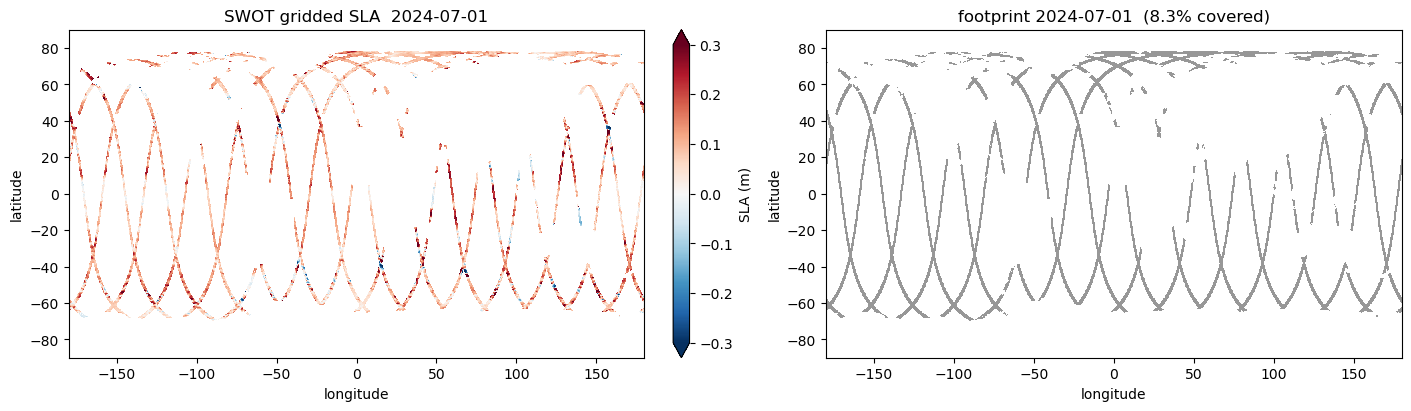

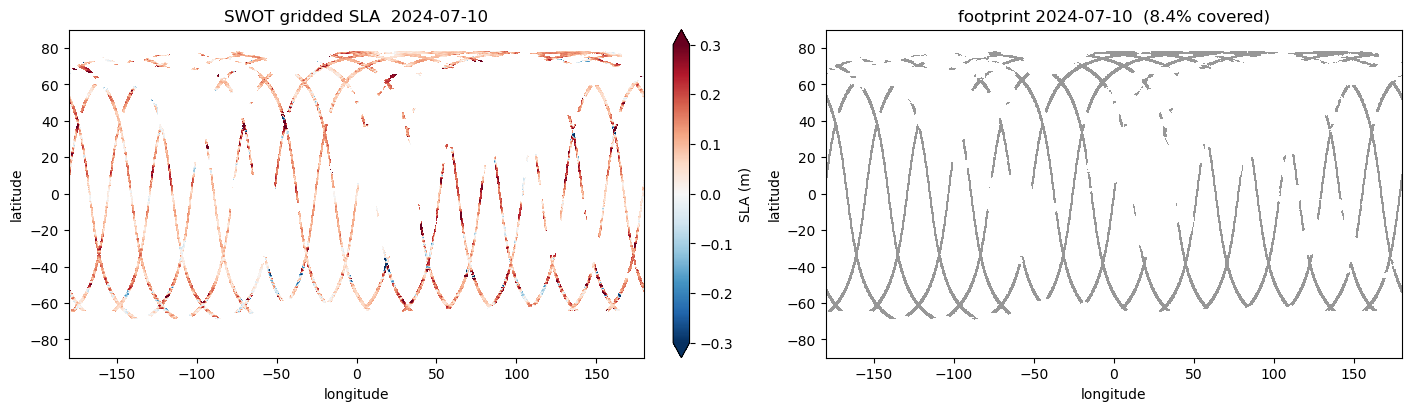

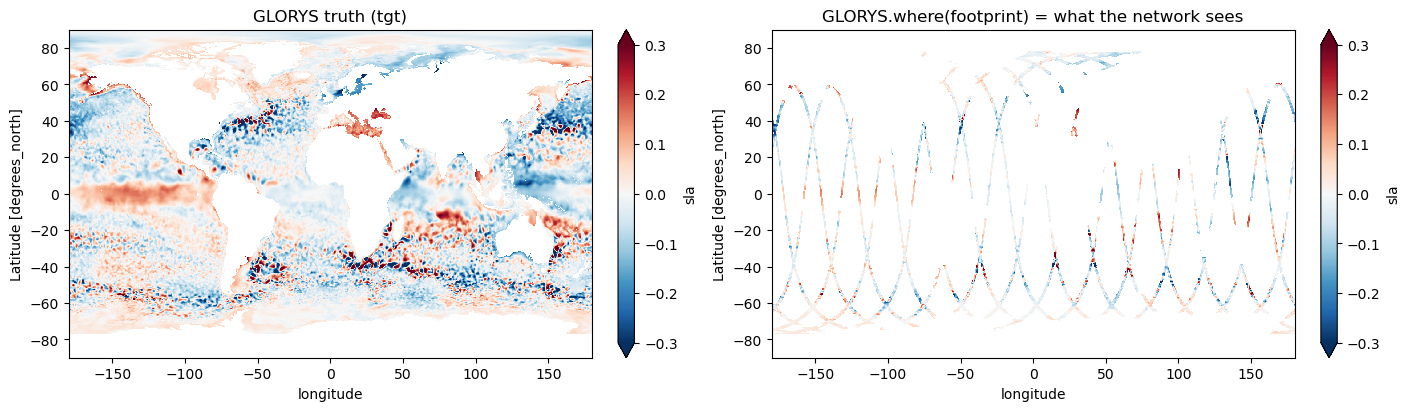

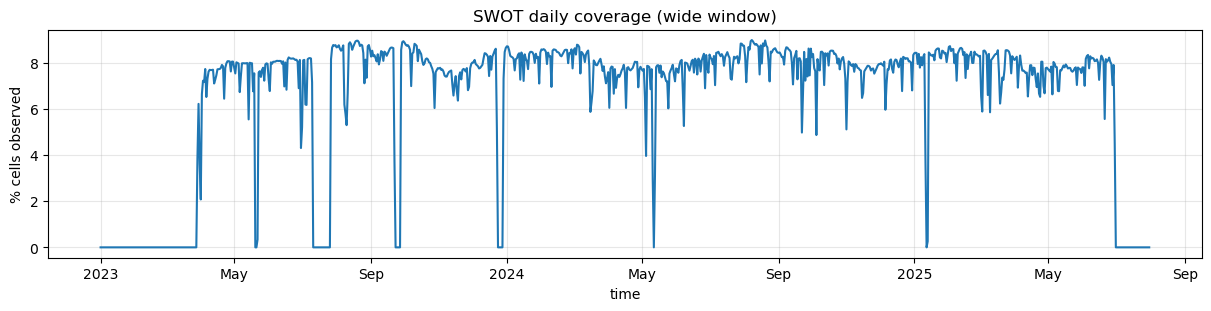

In [8]:
for d in PLOT_DATES:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
    gridded_real.sla.sel(time=d).plot(ax=ax1, cmap='RdBu_r', vmin=-0.3, vmax=0.3,
                                      cbar_kwargs={'label': 'SLA (m)'})
    ax1.set_title(f'{TAG} gridded SLA  {d}')
    mask_365.sel(time=d).plot(ax=ax2, add_colorbar=False, cmap='Greys_r')
    ax2.set_title(f'footprint {d}  ({100 * float(coverage.sel(time=d)):.1f}% covered)')
    fig.savefig(FIG_DIR / f'{TAG}_{d}.png', dpi=110); plt.show()
 
# alignment check: GLORYS truth vs GLORYS masked by one footprint day (stripes must sit on ocean)
day0 = mask_365.isel(time=5)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
glorys['sla'].isel(time=5).plot(ax=a1, cmap='RdBu_r', vmin=-0.3, vmax=0.3)
a1.set_title('GLORYS truth (tgt)')
glorys['sla'].isel(time=5).where(np.isfinite(day0.values)).plot(ax=a2, cmap='RdBu_r', vmin=-0.3, vmax=0.3)
a2.set_title('GLORYS.where(footprint) = what the network sees')
fig.savefig(FIG_DIR / f'{TAG}_alignment_check.png', dpi=110); plt.show()
 
fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
(100 * coverage).plot(ax=ax); ax.grid(alpha=.3)
ax.set(ylabel='% cells observed', title=f'{TAG} daily coverage (wide window)')
fig.savefig(FIG_DIR / f'{TAG}_coverage.png', dpi=110); plt.show()

## 6. Config wiring (same for both configs; only the file names differ by TAG)

base.yaml:
  datamodule.input_da:
    tgt_path: /SCRATCH/n23nguye/glorys12_2010_2019_daily_sla_4th_target_gridded_alongtrack.nc
    tgt_var: sla
    inp_path: <OUT_DIR>/mask_<TAG>_2024_365d.nc
    inp_var: mask
params.yaml:
  input_data: <OUT_DIR>/alongtrack_<TAG>_real_2023-12-01_2025-01-31.nc
  input_var: sla_unfiltered

Run once with USE_KARIN=False (nadir-only), once with USE_KARIN=True (nadirs+SWOT).
Coverage should be clearly higher in the KaRIn run -- that's the swath.